# 04 — Dataset, augmentation and model check
- Images are read as grayscale, copied to 3 channels (the pretrained model expects 3), padded to 384x384 with the aspect ratio preserved, and normalized with ImageNet statistics.
- The target is normalized as `(boneage - mean) / std` using train statistics, and converted back at prediction time.
- The cells below check an augmented train batch and the model's forward pass.

In [1]:
# On Colab: mount Drive and work from the project's notebooks folder
import os, sys
if "google.colab" in sys.modules and not os.getcwd().endswith("notebooks"):
    from google.colab import drive
    drive.mount("/content/drive")
    %cd /content/drive/MyDrive/bone-age/notebooks
%run 00_common.ipynb

In [2]:
df, stats = load_splits()
print(f"target mean/std (train): {stats[0]:.2f} / {stats[1]:.2f}")
loader = make_loader(df, "train", stats)
imgs, sexes, targets = next(iter(loader))
print("image:", tuple(imgs.shape), imgs.dtype, "| sex:", tuple(sexes.shape), "| target:", tuple(targets.shape))

target mean/std (train): 127.32 / 41.23


image: (16, 3, 384, 384) torch.float32 | sex: (16, 1) | target: (16, 1)


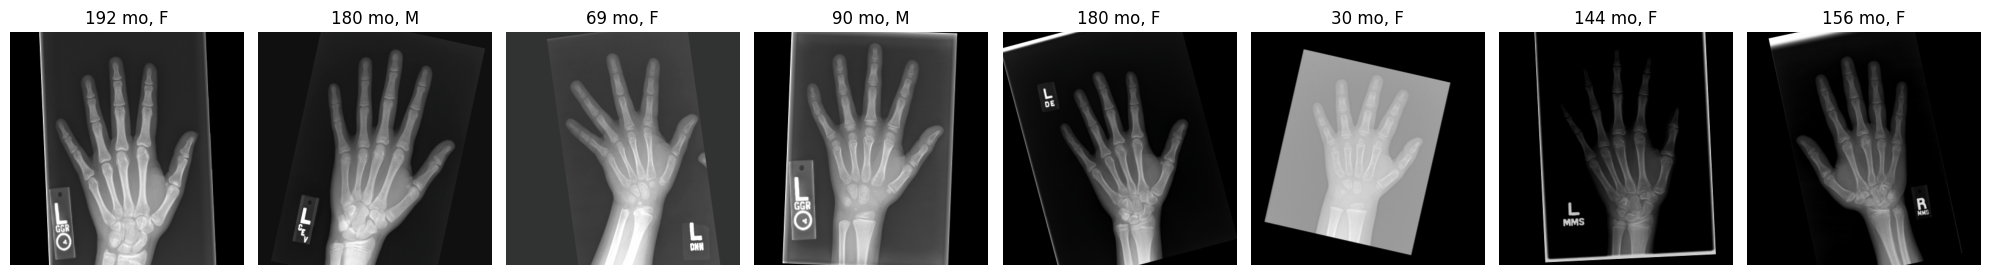

In [3]:
fig = show_batch(loader)
fig.savefig(OUTPUT_DIR / "augmented_batch.png", dpi=100)
plt.show()

In [4]:
model = BoneAgeModel().to(DEVICE)
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16):
    out = model(imgs.to(DEVICE), sexes.to(DEVICE))
print(f"backbone={BACKBONE} | params={sum(p.numel() for p in model.parameters()) / 1e6:.1f}M | output={tuple(out.shape)}")

backbone=efficientnet_b0 | params=4.3M | output=(16, 1)
